<a href="https://colab.research.google.com/github/Ecem6/GROUP33_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Drive'ı Bağlama
from google.colab import drive
drive.mount('/content/drive')

# Dosya yolu
file_path = '/content/drive/MyDrive/Kaggle_Jigsaw/train.csv'

# 2. Veriyi Okuma
df = pd.read_csv(file_path)

# 3. Veriye İlk Bakış
print("--- Veri Setinin Boyutu (Satır, Sütun) ---")
print(df.shape)

print("\n--- Veri Setinin İlk 5 Satırı ---")
display(df.head())

print("\n--- Veri Seti Bilgileri ve Veri Tipleri ---")
df.info()

# 4. Eksik (Null) Değer Kontrolü
# Hangi sütunda kaç tane eksik veri var?
print("\n--- Eksik Veri Kontrolü ---")
print(df.isnull().sum())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- Veri Setinin Boyutu (Satır, Sütun) ---
(2029, 9)

--- Veri Setinin İlk 5 Satırı ---


,row_id,body,rule,subreddit,positive_example_1,positive_example_2,negative_example_1,negative_example_2,rule_violation
0,0,Banks don't want you to know this! Click here ...,"No Advertising: Spam, referral links, unsolici...",Futurology,If you could tell your younger self something ...,hunt for lady for jack off in neighbourhood ht...,Watch Golden Globe Awards 2017 Live Online in ...,"DOUBLE CEE x BANDS EPPS - ""BIRDS""\n\nDOWNLOAD/...",0
1,1,SD Stream [ ENG Link 1] (http://www.sportsstre...,"No Advertising: Spam, referral links, unsolici...",soccerstreams,[I wanna kiss you all over! Stunning!](http://...,LOLGA.COM is One of the First Professional Onl...,#Rapper \n🚨Straight Outta Cross Keys SC 🚨YouTu...,[15 Amazing Hidden Features Of Google Search Y...,0
2,2,Lol. Try appealing the ban and say you won't d...,No legal advice: Do not offer or request legal...,pcmasterrace,Don't break up with him or call the cops. If ...,It'll be dismissed: https://en.wikipedia.org/w...,Where is there a site that still works where y...,Because this statement of his is true. It isn'...,1
3,3,she will come your home open her legs with an...,"No Advertising: Spam, referral links, unsolici...",sex,Selling Tyrande codes for 3€ to paypal. PM. \n...,tight pussy watch for your cock get her at thi...,NSFW(obviously) http://spankbang.com/iy3u/vide...,Good News ::Download WhatsApp 2.16.230 APK for...,1
4,4,code free tyrande --->>> [Imgur](http://i.imgu...,"No Advertising: Spam, referral links, unsolici...",hearthstone,wow!! amazing reminds me of the old days.Well...,seek for lady for sex in around http://p77.pl/...,must be watch movie https://sites.google.com/s...,We're streaming Pokemon Veitnamese Crystal RIG...,1



--- Veri Seti Bilgileri ve Veri Tipleri ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2029 entries, 0 to 2028
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   row_id              2029 non-null   int64 
 1   body                2029 non-null   object
 2   rule                2029 non-null   object
 3   subreddit           2029 non-null   object
 4   positive_example_1  2029 non-null   object
 5   positive_example_2  2029 non-null   object
 6   negative_example_1  2029 non-null   object
 7   negative_example_2  2029 non-null   object
 8   rule_violation      2029 non-null   int64 
dtypes: int64(2), object(7)
memory usage: 142.8+ KB

--- Eksik Veri Kontrolü ---
row_id                0
body                  0
rule                  0
subreddit             0
positive_example_1    0
positive_example_2    0
negative_example_1    0
negative_example_2    0
rule_violation        0
dtype: int64


--- Sınıf Dağılımı (rule_violation) ---
rule_violation
1    50.813208
0    49.186792
Name: proportion, dtype: float64


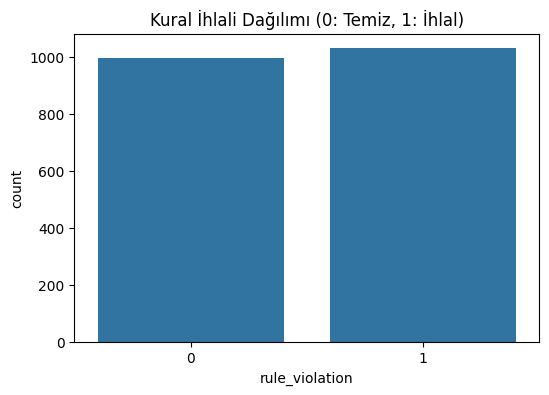


--- Kelime Sayısı İstatistikleri ---
count    2029.000000
mean       27.963036
std        21.230214
min         1.000000
25%        11.000000
50%        22.000000
75%        39.000000
max        97.000000
Name: kelime_sayisi, dtype: float64

--- Temizlenmiş Metin Örnekleri ---


,body,clean_body
0,Banks don't want you to know this! Click here ...,banks dont want you to know this click here to...
1,SD Stream [ ENG Link 1] (http://www.sportsstre...,sd stream
2,Lol. Try appealing the ban and say you won't d...,lol try appealing the ban and say you wont do ...
3,she will come your home open her legs with an...,she will come your home open her legs with and...
4,code free tyrande --->>> [Imgur](http://i.imgu...,code free tyrande for you and your friend 2 co...


In [ ]:
import re
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Sınıf Dağılımı ve Uzunluk Analizi ---
metin_sutunu = 'body'
etiket_sutunu = 'rule_violation'

print(f"--- Sınıf Dağılımı ({etiket_sutunu}) ---")
print(df[etiket_sutunu].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=etiket_sutunu)
plt.title('Kural İhlali Dağılımı (0: Temiz, 1: İhlal)')
plt.show()

df['kelime_sayisi'] = df[metin_sutunu].apply(lambda x: len(str(x).split()))
print("\n--- Kelime Sayısı İstatistikleri ---")
print(df['kelime_sayisi'].describe())

# --- 2. Metin Temizleme (Text Preprocessing) ---
def metin_temizle(text):
    text = str(text).lower()
    # URL'leri (linkleri) sil
    text = re.sub(r'http\S+', '', text)
    # [Imgur] gibi Markdown link yapılarını sil
    text = re.sub(r'\[.*?\]', '', text)
    # Yeni satır (\n) karakterlerini boşlukla değiştir
    text = re.sub(r'\n+', ' ', text)
    # Sadece harfleri ve sayıları tut, noktalama ve emojileri sil
    text = re.sub(r'[^a-z0-9\s]', '', text)
    # Yan yana oluşmuş fazla boşlukları tek boşluğa düşür
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_body'] = df['body'].apply(metin_temizle)
df['clean_rule'] = df['rule'].apply(metin_temizle)

print("\n--- Temizlenmiş Metin Örnekleri ---")
display(df[['body', 'clean_body']].head())

In [ ]:
import re

# Temizleme fonksiyonunu tekrar tanımlıyoruz
def metin_temizle(text):
    text = str(text).lower()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'\n+', ' ', text)
    text = re.sub(r'[^a-z0-9\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Sütunları yeniden oluşturuyoruz
df['clean_body'] = df['body'].apply(metin_temizle)
df['clean_rule'] = df['rule'].apply(metin_temizle)

# Sütunların başarıyla oluştuğunu kontrol ediyoruz
print(df.columns)

Index(['row_id', 'body', 'rule', 'subreddit', 'positive_example_1',
       'positive_example_2', 'negative_example_1', 'negative_example_2',
       'rule_violation', 'clean_body', 'clean_rule'],
      dtype='object')


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# 1. Metinleri Birleştirme (Kural + Yorum)
df['combined_text'] = df['clean_rule'] + " " + df['clean_body']

X = df['combined_text']
y = df['rule_violation']

# 2. Veriyi Eğitim (Train) ve Doğrulama (Validation) Olarak Bölme
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. TF-IDF ile Metni Vektörleştirme
vectorizer = TfidfVectorizer(max_features=5000)

X_train_tfidf = vectorizer.fit_transform(X_train)

# transform işlemi validation (ve test) verisine uygulanır
X_val_tfidf = vectorizer.transform(X_val)

# 4. Makine Öğrenmesi Modelini Kurma ve Eğitme
# class_weight='balanced': Verimizdeki azınlık sınıfını (kural ihlallerini) modelin es geçmemesi için ağırlıklandırıyoruz.
model = LogisticRegression(class_weight='balanced', random_state=42)
model.fit(X_train_tfidf, y_train)

# 5. Modelin Performansını Ölçme (Tahminler)
y_pred = model.predict(X_val_tfidf) # 0 veya 1 olarak kesin tahminler
y_pred_proba = model.predict_proba(X_val_tfidf)[:, 1] # Kaggle ROC-AUC için 1 olma olasılıkları

print("--- Sınıflandırma Raporu (Classification Report) ---")
print(classification_report(y_val, y_pred))

print(f"ROC-AUC Skoru: {roc_auc_score(y_val, y_pred_proba):.4f}")

--- Sınıflandırma Raporu (Classification Report) ---
              precision    recall  f1-score   support

           0       0.77      0.67      0.72       200
           1       0.72      0.81      0.76       206

    accuracy                           0.74       406
   macro avg       0.75      0.74      0.74       406
weighted avg       0.75      0.74      0.74       406

ROC-AUC Skoru: 0.8241
